In [34]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Look for CSVs in the same folder as this notebook
DATA_DIR = ""
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [35]:
FILES = {
    "mp_quant":      "surveympquantification.csv",
    "soil_props":    "surveysoilproperties.csv",
    "questionnaire": "surveyquestionnaire.csv",
    "mp_id":         "surveympidentification.csv",
    "std_quant":     "standardmpquantification.csv",
    "std_polymer":   "standardpolymerid.csv",
    "std_lib_uk":    "standardpolymerlibrarycomparisonuk.csv",
    "lab_meta":      "laboratorymetadata.csv",
}

data = {}
for key, filename in FILES.items():
    path = os.path.join(DATA_DIR, filename)
    if os.path.exists(path):
        try:
            # encoding="latin1" handles the special characters like 'µ' and '±'
            data[key] = pd.read_csv(path, encoding="latin1")
            print(f"[OK] {key}: {data[key].shape[0]} rows x {data[key].shape[1]} cols")
        except Exception as e:
            data[key] = None
            print(f"[ERROR] Could not read {filename}: {e}")
    else:
        data[key] = None
        print(f"[MISSING] {path}")

[OK] mp_quant: 576 rows x 5 cols
[OK] soil_props: 576 rows x 9 cols
[OK] questionnaire: 192 rows x 49 cols
[OK] mp_id: 6851 rows x 5 cols
[OK] std_quant: 188 rows x 4 cols
[OK] std_polymer: 1440 rows x 5 cols
[OK] std_lib_uk: 180 rows x 5 cols
[OK] lab_meta: 8 rows x 45 cols


In [36]:
for name, df in data.items():
    if df is None:
        continue
    print("=" * 60)
    print(f"DATASET: {name}   shape={df.shape}")
    print("-" * 60)
    print(df.dtypes)
    print(df.head(3))
    print()

DATASET: mp_quant   shape=(576, 5)
------------------------------------------------------------
Site             str
Country          str
Depth          int64
Z            float64
MP_number    float64
dtype: object
  Site Country  Depth         Z    MP_number
0   E1   Egypt     10 -0.279410   877.381883
1   E1   Egypt     20 -0.662864   744.294969
2   E1   Egypt     30  1.501901  1495.628188

DATASET: soil_props   shape=(576, 9)
------------------------------------------------------------
Site Code        str
Country          str
Depth          int64
pH           float64
EC           float64
NH4          float64
NO3          float64
DOC          float64
PO4          float64
dtype: object
  Site Code Country  Depth    pH     EC    NH4   NO3     DOC   PO4
0        E1   Egypt     10  8.95  290.0  33.19  2.37  264.28  6.93
1        E1   Egypt     20  9.20  337.0  25.40  3.18  199.75  7.10
2        E1   Egypt     30  9.04  297.0  33.32  3.81  129.42  8.88

DATASET: questionnaire   shape=(19

In [37]:
for name, df in data.items():
    if df is None:
        continue
    report = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(1),
        "n_unique": df.nunique(),
    })
    print(f"\n--- {name} (duplicate rows = {df.duplicated().sum()}) ---")
    print(report.sort_values("pct_missing", ascending=False).head(10))


--- mp_quant (duplicate rows = 0) ---
             dtype  n_missing  pct_missing  n_unique
MP_number  float64          4          0.7       443
Z          float64          4          0.7       429
Site           str          0          0.0       192
Depth        int64          0          0.0         3
Country        str          0          0.0         5

--- soil_props (duplicate rows = 0) ---
             dtype  n_missing  pct_missing  n_unique
DOC        float64          6          1.0       491
Site Code      str          0          0.0       192
Country        str          0          0.0         5
pH         float64          0          0.0       286
Depth        int64          0          0.0         3
EC         float64          0          0.0       503
NH4        float64          0          0.0       413
NO3        float64          0          0.0       445
PO4        float64          0          0.0       524

--- questionnaire (duplicate rows = 0) ---
                            

In [38]:
NA_TOKENS = ["n/a", "N/A", "na", "NaN", "", " "]

def standardise_missing(df):
    """Turn common 'missing' text markers into real NaN, and strip spaces."""
    df = df.replace(NA_TOKENS, np.nan)
    for col in df.columns:
        if df[col].dtype == "object":
            df[col] = df[col].astype(str).str.strip()
            df[col] = df[col].replace("nan", np.nan)   # fix strings turned into 'nan'
    return df

def coerce_numeric(df, cols):
    """Turn text columns into numbers; anything not a number becomes NaN."""
    for c in cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

mpq_raw = data["mp_quant"].copy()          # keep the raw copy for before/after
mpq = standardise_missing(mpq_raw.copy())
mpq = coerce_numeric(mpq, ["Depth", "MP_number"])

# Before/after missing counts — this table goes in the report
print("Missing values BEFORE cleaning (mp_quant):")
print(mpq_raw.isna().sum())

print("\nMissing values AFTER cleaning (mp_quant):")
print(mpq.isna().sum())

mpq_raw = data["mp_quant"].copy()          # keep the raw copy for before/after
mpq = standardise_missing(mpq_raw.copy())
mpq = coerce_numeric(mpq, ["Depth", "MP_number"])

# Before/after missing counts — this table goes in the report
print("Missing values BEFORE cleaning (mp_quant):")
print(mpq_raw.isna().sum())

print("\nMissing values AFTER cleaning (mp_quant):")
print(mpq.isna().sum())

soil = standardise_missing(data["soil_props"].copy())
soil = coerce_numeric(soil, ["Depth", "pH", "EC", "NH4", "NO3", "DOC", "PO4"])
soil = soil.rename(columns={"Site Code": "Site"})   # make merge keys match
print("soil_props shape:", soil.shape)
print("soil_props columns:", list(soil.columns))

soil = standardise_missing(data["soil_props"].copy())
soil = coerce_numeric(soil, ["Depth", "pH", "EC", "NH4", "NO3", "DOC", "PO4"])
soil = soil.rename(columns={"Site Code": "Site"})   # make merge keys match
print("soil_props shape:", soil.shape)
print("soil_props columns:", list(soil.columns))

qn = standardise_missing(data["questionnaire"].copy())
qn = coerce_numeric(qn, ["Max_cultivation_depth", "Annual_average_rainfall",
                          "Annual_average_air_temperature", "PMF_use_duration",
                          "Compost_quantity_per_year", "Compost_use_duration"])
qn = qn.rename(columns={"Site_Code": "Site"})
print("questionnaire shape:", qn.shape)

Missing values BEFORE cleaning (mp_quant):
Site         0
Country      0
Depth        0
Z            4
MP_number    4
dtype: int64

Missing values AFTER cleaning (mp_quant):
Site         0
Country      0
Depth        0
Z            4
MP_number    4
dtype: int64
Missing values BEFORE cleaning (mp_quant):
Site         0
Country      0
Depth        0
Z            4
MP_number    4
dtype: int64

Missing values AFTER cleaning (mp_quant):
Site         0
Country      0
Depth        0
Z            4
MP_number    4
dtype: int64
soil_props shape: (576, 9)
soil_props columns: ['Site', 'Country', 'Depth', 'pH', 'EC', 'NH4', 'NO3', 'DOC', 'PO4']
soil_props shape: (576, 9)
soil_props columns: ['Site', 'Country', 'Depth', 'pH', 'EC', 'NH4', 'NO3', 'DOC', 'PO4']
questionnaire shape: (192, 49)


In [39]:
# 1) Depth must be 10, 20, or 30
bad_depth = mpq.loc[~mpq["Depth"].isin([10, 20, 30]) & mpq["Depth"].notna()]
print(f"Rows with unexpected depth values: {len(bad_depth)}")

# 2) MP_number must be non-negative
print(f"Negative MP_number values: {(mpq['MP_number'] < 0).sum()}")

# 3) No duplicate (Site, Country, Depth) rows in a clean survey
dups = mpq.duplicated(subset=["Site", "Country", "Depth"]).sum()
print(f"Duplicate (Site, Country, Depth) rows: {dups}")

# 4) Missing in key columns
print("\nMissing in key columns:")
print(mpq[["Site", "Country", "Depth", "MP_number"]].isna().sum())

Rows with unexpected depth values: 0
Negative MP_number values: 0
Duplicate (Site, Country, Depth) rows: 0

Missing in key columns:
Site         0
Country      0
Depth        0
MP_number    4
dtype: int64


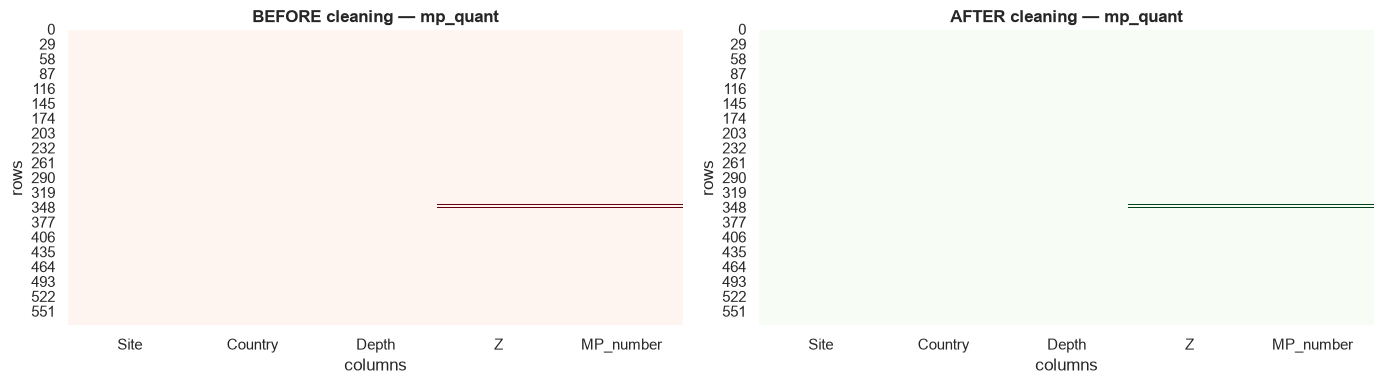

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.heatmap(mpq_raw.isna(), cbar=False, cmap="Reds", ax=axes[0])
axes[0].set_title("BEFORE cleaning — mp_quant")
axes[0].set_xlabel("columns")
axes[0].set_ylabel("rows")

sns.heatmap(mpq.isna(), cbar=False, cmap="Greens", ax=axes[1])
axes[1].set_title("AFTER cleaning — mp_quant")
axes[1].set_xlabel("columns")
axes[1].set_ylabel("rows")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_missing_before_after.png"), dpi=120)
plt.show()

In [41]:
# Questionnaire has 1 row per site, so we only need it once per site
qn_slim = qn.drop_duplicates(subset=["Site", "Country"])

master = mpq.merge(
    soil,
    on=["Site", "Country", "Depth"],
    how="left"
).merge(
    qn_slim,
    on=["Site", "Country"],
    how="left",
    suffixes=("", "_qn")
)

print("mp_quant rows:      ", len(mpq))
print("master table rows:  ", len(master))
assert len(master) == len(mpq), "Merge changed row count — check join keys!"
print("✓ Row count preserved — merge was clean")

print("\nUnique sites:", master["Site"].nunique())
print("Unique countries:", master["Country"].dropna().unique().tolist())
print("Master columns:", len(master.columns))

mp_quant rows:       576
master table rows:   576
✓ Row count preserved — merge was clean

Unique sites: 192
Unique countries: ['Egypt', 'Vietnam', 'Sri Lanka', 'China', 'India']
Master columns: 58


In [42]:
summary = master.groupby("Country")["MP_number"].agg(
    n="count", mean="mean", median="median",
    std="std", min="min", max="max"
).round(2)

print(summary)
summary.to_csv("mp_by_country_summary.csv")

             n     mean   median      std     min       max
Country                                                    
China      120    76.57    41.38    91.94    2.68    570.00
Egypt      120  1122.68   974.36   711.38  230.21   5861.86
India       96    69.56    59.46    42.92    0.00    190.29
Sri Lanka  116  3136.71  1110.89  5931.86    2.76  42549.63
Vietnam    120     5.32     4.40     5.22    0.60     53.80


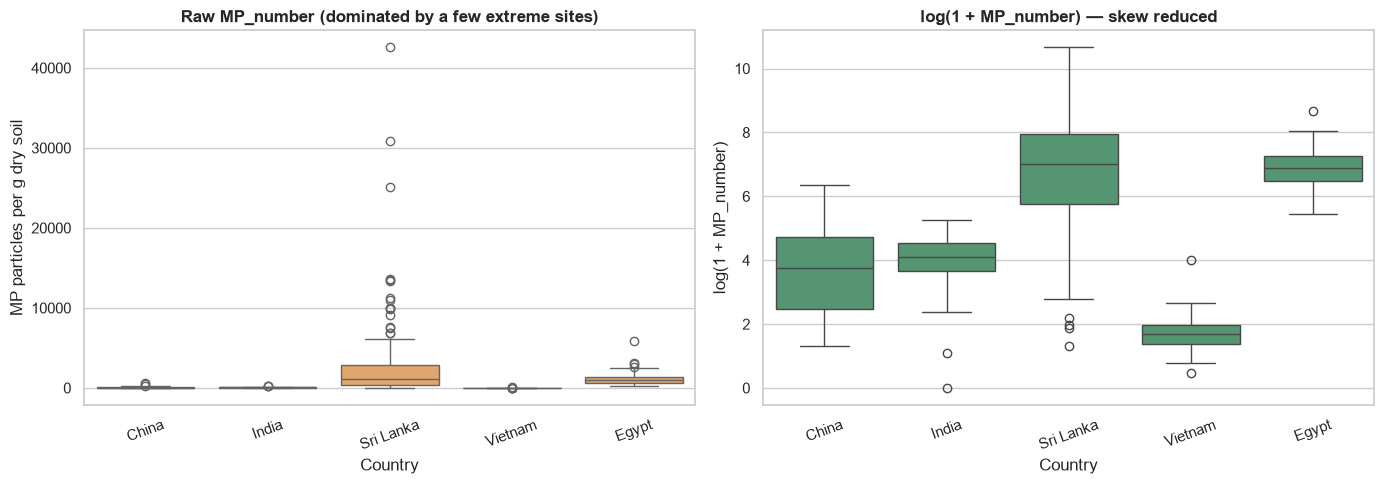

In [43]:
master["log_MP"] = np.log1p(master["MP_number"])

country_order = ["China", "India", "Sri Lanka", "Vietnam", "Egypt"]
master["Country"] = pd.Categorical(master["Country"], categories=country_order, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=master, x="Country", y="MP_number", ax=axes[0], color="#f2a65a")
axes[0].set_title("Raw MP_number (dominated by a few extreme sites)")
axes[0].set_ylabel("MP particles per g dry soil")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=master, x="Country", y="log_MP", ax=axes[1], color="#4c9f70")
axes[1].set_title("log(1 + MP_number) — skew reduced")
axes[1].set_ylabel("log(1 + MP_number)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig2_raw_vs_log.png"), dpi=120)
plt.show()

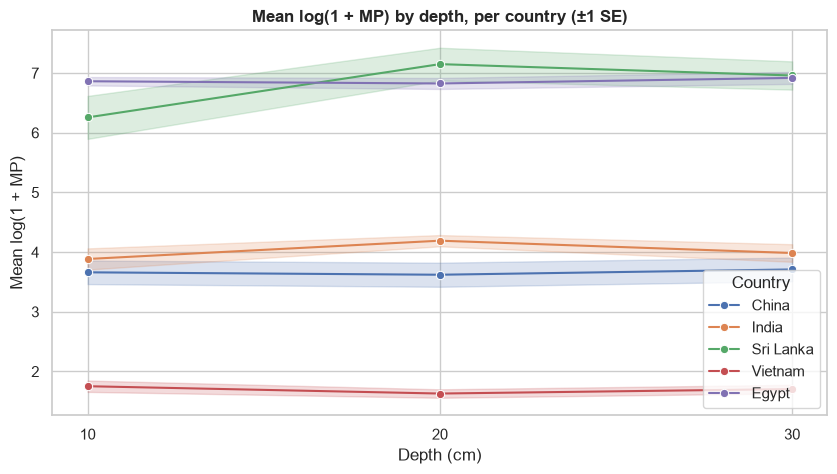

In [44]:
depth_data = master.dropna(subset=["Depth", "MP_number"])

plt.figure(figsize=(10, 5))
sns.lineplot(data=depth_data, x="Depth", y="log_MP",
             hue="Country", marker="o", errorbar="se")
plt.title("Mean log(1 + MP) by depth, per country (±1 SE)")
plt.xlabel("Depth (cm)")
plt.ylabel("Mean log(1 + MP)")
plt.xticks([10, 20, 30])
plt.savefig(os.path.join(FIG_DIR, "fig3_depth_trend.png"), dpi=120)
plt.show()

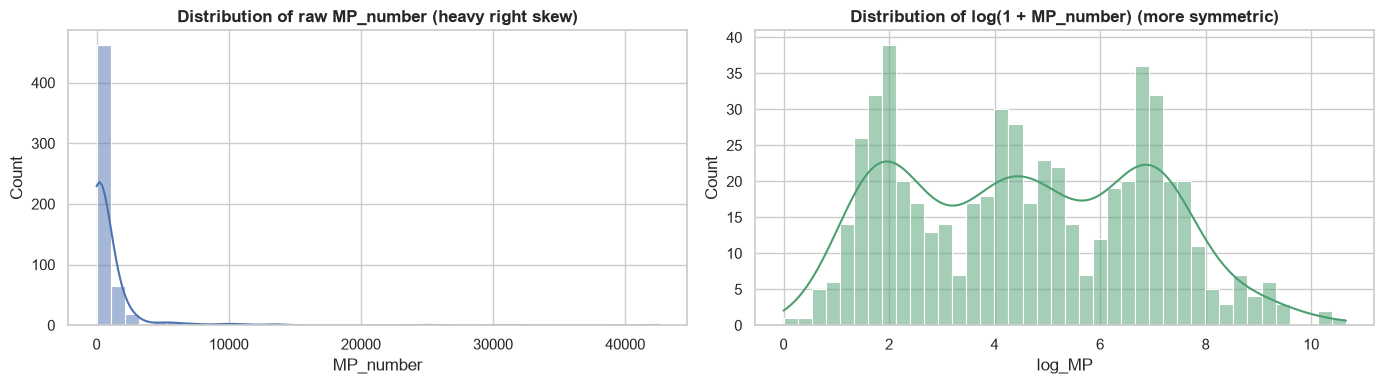

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(master["MP_number"].dropna(), bins=40, kde=True, color="#4c72b0", ax=axes[0])
axes[0].set_title("Distribution of raw MP_number (heavy right skew)")

sns.histplot(master["log_MP"].dropna(), bins=40, kde=True, color="#4c9f70", ax=axes[1])
axes[1].set_title("Distribution of log(1 + MP_number) (more symmetric)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig4_distribution.png"), dpi=120)
plt.show()

In [46]:
numeric_vars = ["pH", "EC", "NH4", "NO3", "DOC", "PO4",
                "Annual_average_rainfall", "Annual_average_air_temperature",
                "PMF_use_duration"]
numeric_vars = [v for v in numeric_vars if v in master.columns]

rows = []
for v in numeric_vars:
    pair = master[["log_MP", v]].dropna()
    if len(pair) >= 5:
        r = pair["log_MP"].corr(pair[v], method="spearman")
        rows.append({"variable": v, "n": len(pair), "spearman_r": round(r, 3)})

assoc = pd.DataFrame(rows).sort_values("spearman_r", key=abs, ascending=False)
print(assoc.to_string(index=False))
assoc.to_csv("associations_spearman.csv", index=False)

                      variable   n  spearman_r
                           NH4 572       0.595
                           DOC 566       0.541
              PMF_use_duration 572      -0.453
       Annual_average_rainfall 572      -0.416
                           PO4 572      -0.412
Annual_average_air_temperature 572       0.358
                            EC 572      -0.306
                           NO3 572       0.242
                            pH 572       0.219


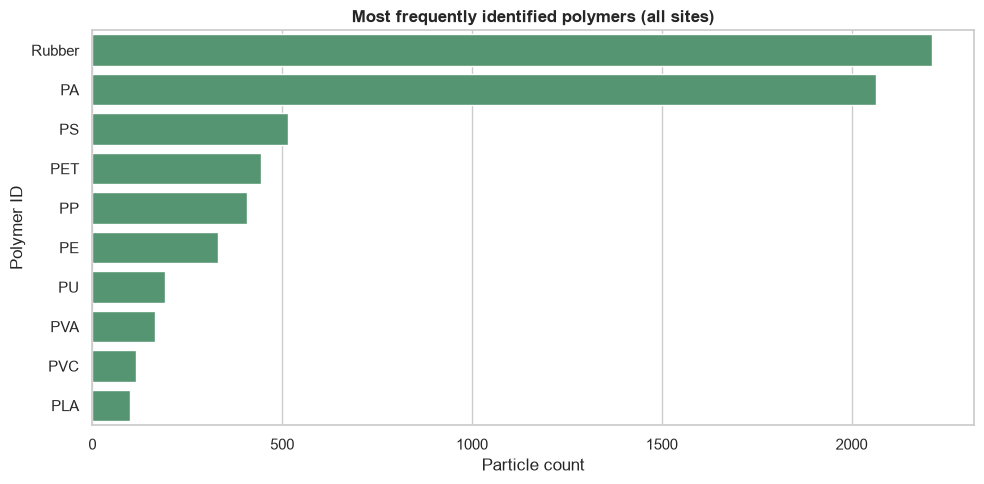

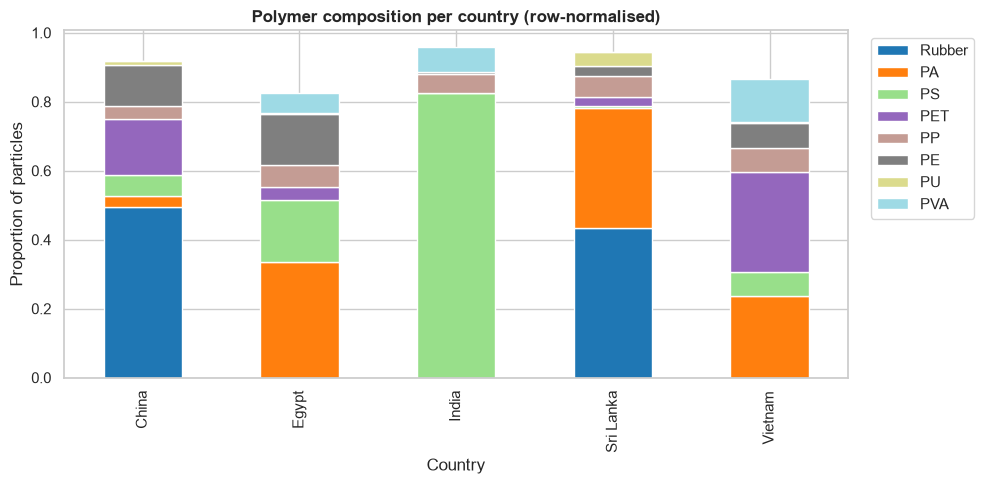

In [47]:
mpid = data["mp_id"].copy()
mpid["ID"] = mpid["ID"].fillna("Unidentified")

# Top 10 polymers overall
top_types = mpid["ID"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_types.values, y=top_types.index, color="#4c9f70")
plt.title("Most frequently identified polymers (all sites)")
plt.xlabel("Particle count")
plt.ylabel("Polymer ID")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_top_polymers.png"), dpi=120)
plt.show()

# Composition per country (row-normalised so countries are comparable)
comp = mpid.groupby(["Country", "ID"]).size().unstack(fill_value=0)
keep = comp.sum().sort_values(ascending=False).head(8).index
prop = comp[keep].div(comp.sum(axis=1), axis=0)

prop.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab20")
plt.title("Polymer composition per country (row-normalised)")
plt.ylabel("Proportion of particles")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig6_composition.png"), dpi=120)
plt.show()

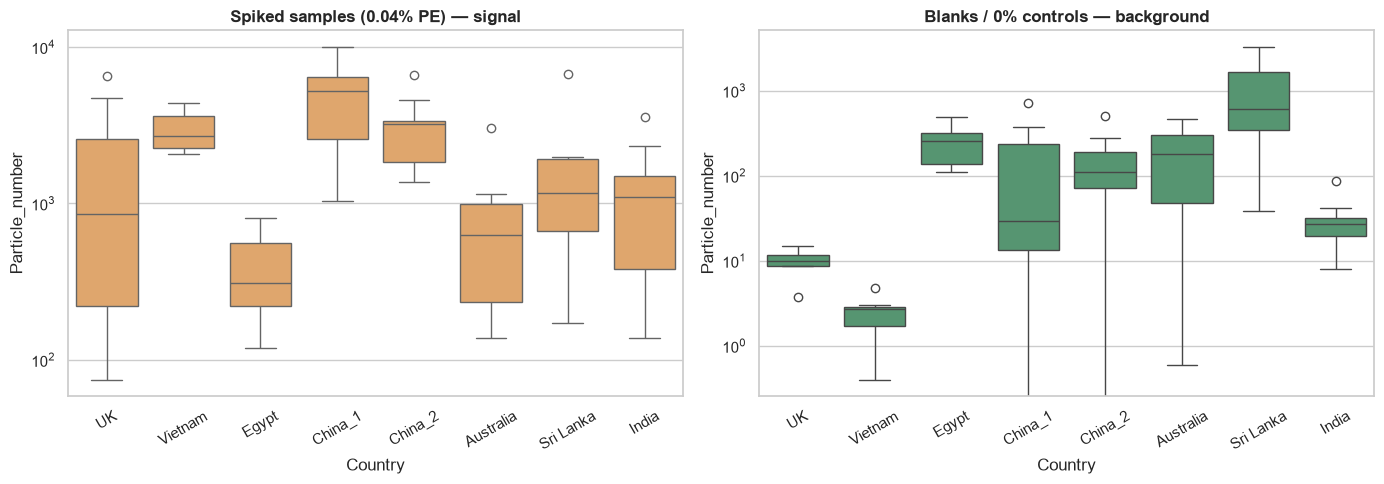

In [48]:
stdq = data["std_quant"].copy()
stdq["Sample"] = stdq["Sample"].astype(str)

# Split the "spiked" (0.04%) from the blanks/0% controls
spiked = stdq[stdq["Sample"].str.contains("0.04")]
blanks = stdq[stdq["Sample"].str.contains("0%|Blank", regex=True)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=spiked, x="Country", y="Particle_number", ax=axes[0], color="#f2a65a")
axes[0].set_yscale("log")
axes[0].set_title("Spiked samples (0.04% PE) — signal")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=blanks, x="Country", y="Particle_number", ax=axes[1], color="#4c9f70")
axes[1].set_yscale("log")
axes[1].set_title("Blanks / 0% controls — background")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig7_controls.png"), dpi=120)
plt.show()

In [49]:
# Save the merged master file
master.to_csv("master_soil_microplastics.csv", index=False)
print("Saved master table: master_soil_microplastics.csv")

# Simple preprocessing summary table
summary_rows = []
for name, df in data.items():
    if df is None:
        continue
    summary_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": df.shape[1],
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
    })

prep_summary = pd.DataFrame(summary_rows)
print("\n" + "=" * 60)
print("PREPROCESSING SUMMARY")
print("=" * 60)
print(prep_summary.to_string(index=False))
prep_summary.to_csv("preprocessing_summary.csv", index=False)

Saved master table: master_soil_microplastics.csv

PREPROCESSING SUMMARY
      dataset  rows  columns  duplicate_rows  missing_cells
     mp_quant   576        5               0              8
   soil_props   576        9               0              6
questionnaire   192       49               0            656
        mp_id  6851        5             236              0
    std_quant   188        4               0              0
  std_polymer  1440        5               0            220
   std_lib_uk   180        5               0              0
     lab_meta     8       45               0             98
